# 7115056075 HW2：零售需求多元線性回歸分析

資料來源：[Kaggle - Retail Store Inventory and Demand Forecasting](https://www.kaggle.com/datasets/atomicd/retail-store-inventory-and-demand-forecasting)

本 Notebook 依 CRISP-DM 流程完成資料理解、資料準備、前 20 名特徵選擇、多元線性回歸、模型評估與部署規劃。所有前處理器與特徵選擇器都只在訓練資料上擬合，以避免資料洩漏。

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_rows", 100)
plt.style.use("seaborn-v0_8-whitegrid")

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\c2h5o\\AppData\\Local\\matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## 1. Business Understanding（商業理解）

零售業同時承受缺貨與庫存過量風險。本研究以 `Demand` 為預測目標，評估銷售量、訂購量、價格、促銷、天氣、季節與疫情等因素，建立可解釋的多元線性回歸模型。模型除點預測外，也提供 95% 預測區間，協助管理者衡量單筆需求預測的不確定性。

## 2. Data Understanding（資料理解）

資料集含 16 個欄位，其中 `Demand` 為目標、`Date` 為日期欄位，其餘 14 個欄位為候選特徵。下列程式檢查資料規模、日期範圍、缺失值、重複資料與描述統計。

In [2]:
df = pd.read_csv("sales_data.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="raise")

data_overview = pd.DataFrame({
    "value": [
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        df["Date"].min().date().isoformat(),
        df["Date"].max().date().isoformat(),
    ]
}, index=["rows", "columns", "missing_values", "duplicate_rows", "date_start", "date_end"])

display(data_overview)
display(df.head())
display(df.describe(include="all").T)

,value
rows,76000
columns,16
missing_values,0
duplicate_rows,0
date_start,2022-01-01
date_end,2024-01-30


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Date,76000,NaN,NaN,NaN,2023-01-15 12:00:00,2022-01-01 00:00:00,2022-07-09 18:00:00,2023-01-15 12:00:00,2023-07-24 06:00:00,2024-01-30 00:00:00,NaN
Store ID,76000,5,S001,15200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product ID,76000,20,P0001,3800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,76000,5,Groceries,30400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,76000,4,North,30400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inventory Level,76000.0,NaN,NaN,NaN,301.062842,0.0,136.0,227.0,408.0,2267.0,226.510161
Units Sold,76000.0,NaN,NaN,NaN,88.827316,0.0,58.0,84.0,114.0,426.0,43.994525
Units Ordered,76000.0,NaN,NaN,NaN,89.090645,0.0,0.0,0.0,121.0,1616.0,162.404627
Price,76000.0,NaN,NaN,NaN,67.726028,4.74,31.9975,64.5,95.83,228.03,39.377899
Discount,76000.0,NaN,NaN,NaN,9.087039,0.0,5.0,10.0,10.0,25.0,7.475781


## 3. Data Preparation（資料準備）

本作業採固定亂數種子的 80/20 切分，以便重現並與一般回歸作業比較。`Date` 僅用於資料理解，不放入主模型。先切分資料，再於訓練集擬合 Min-Max scaling 與 One-Hot Encoding；測試集只能呼叫 `transform`。

In [3]:
TARGET = "Demand"
MODEL_FEATURES = [column for column in df.columns if column not in [TARGET, "Date"]]

X = df[MODEL_FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

Train shape: (60800, 14)
Test shape : (15200, 14)


In [4]:
numeric_features = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
]
categorical_features = [
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality",
]
binary_features = ["Promotion", "Epidemic"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", MinMaxScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
        ("binary", "passthrough", binary_features),
    ],
    verbose_feature_names_out=False,
)

X_train_processed_array = preprocessor.fit_transform(X_train)
X_test_processed_array = preprocessor.transform(X_test)
processed_feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed_array,
    columns=processed_feature_names,
    index=X_train.index,
).astype(float)
X_test_processed = pd.DataFrame(
    X_test_processed_array,
    columns=processed_feature_names,
    index=X_test.index,
).astype(float)

print("Processed train shape:", X_train_processed.shape)
print("Processed test shape :", X_test_processed.shape)

Processed train shape: (60800, 44)
Processed test shape : (15200, 44)


## 4. Feature Selection（特徵選擇）

使用訓練資料的 `f_regression` 計算單變量線性關聯 F-score，依分數由高至低固定選取前 20 名。p-value 僅作輔助說明，不再作為決定特徵數量的門檻。

In [5]:
TOP_K = 20
selector = SelectKBest(score_func=f_regression, k=TOP_K)
selector.fit(X_train_processed, y_train)

feature_scores = pd.DataFrame({
    "Feature": processed_feature_names,
    "F_Score": selector.scores_,
    "P_Value": selector.pvalues_,
}).sort_values("F_Score", ascending=False, ignore_index=True)
feature_scores.insert(0, "Rank", np.arange(1, len(feature_scores) + 1))

top20_features = feature_scores.head(TOP_K).copy()
selected_features = top20_features["Feature"].tolist()
X_train_selected = X_train_processed[selected_features]
X_test_selected = X_test_processed[selected_features]

top20_features.to_csv(RESULTS_DIR / "top20_features.csv", index=False, encoding="utf-8-sig")
display(top20_features)
print("Selected feature count:", len(selected_features))

,Rank,Feature,F_Score,P_Value
0,1,Units Sold,137207.429068,0.000000e+00
1,2,Units Ordered,21495.847332,0.000000e+00
2,3,Epidemic,9303.635773,0.000000e+00
3,4,Category_Furniture,6317.223660,0.000000e+00
4,5,Category_Groceries,5583.408030,0.000000e+00
5,6,Promotion,5197.681632,0.000000e+00
6,7,Discount,3177.425107,0.000000e+00
7,8,Weather Condition_Sunny,1417.727013,1.023004e-306
8,9,Inventory Level,972.372642,8.584070e-212
9,10,Weather Condition_Rainy,700.009058,2.211201e-153


Selected feature count: 20


## 5. Modeling（建模）

比較三種設定：訓練集平均值基準、全部處理後特徵的線性回歸，以及前 20 名特徵線性回歸。正式主模型為前 20 名版本；另以相同特徵建立 statsmodels OLS，取得統計摘要與預測區間。

In [6]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }


baseline_pred = np.full(len(y_test), y_train.mean(), dtype=float)

full_model = LinearRegression()
full_model.fit(X_train_processed, y_train)
full_pred = full_model.predict(X_test_processed)

selected_model = LinearRegression()
selected_model.fit(X_train_selected, y_train)
selected_pred = selected_model.predict(X_test_selected)

comparison_rows = []
for model_name, prediction_values, feature_count in [
    ("Mean baseline", baseline_pred, 0),
    ("Linear regression - all features", full_pred, X_train_processed.shape[1]),
    ("Linear regression - top 20", selected_pred, len(selected_features)),
]:
    row = {"Model": model_name, "Feature_Count": feature_count}
    row.update(regression_metrics(y_test, prediction_values))
    comparison_rows.append(row)

model_comparison = pd.DataFrame(comparison_rows)
model_comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False, encoding="utf-8-sig")
display(model_comparison)

,Model,Feature_Count,MAE,RMSE,R2
0,Mean baseline,0,37.041649,46.994849,-3.013392e-08
1,Linear regression - all features,44,16.266018,21.813803,7.845422e-01
2,Linear regression - top 20,20,16.551093,22.201103,7.768234e-01


In [7]:
X_train_ols = sm.add_constant(X_train_selected.reset_index(drop=True), has_constant="add")
X_test_ols = sm.add_constant(X_test_selected.reset_index(drop=True), has_constant="add")

ols_model = sm.OLS(y_train.to_numpy(dtype=float), X_train_ols).fit()
prediction_frame = ols_model.get_prediction(X_test_ols).summary_frame(alpha=0.05)

prediction_results = pd.DataFrame({
    "Actual": y_test.to_numpy(dtype=float),
    "Predicted": prediction_frame["mean"].to_numpy(dtype=float),
    "Lower_PI": prediction_frame["obs_ci_lower"].to_numpy(dtype=float),
    "Upper_PI": prediction_frame["obs_ci_upper"].to_numpy(dtype=float),
})
prediction_results["Residual"] = prediction_results["Actual"] - prediction_results["Predicted"]

coverage = float(
    (
        (prediction_results["Actual"] >= prediction_results["Lower_PI"])
        & (prediction_results["Actual"] <= prediction_results["Upper_PI"])
    ).mean()
)
mean_interval_width = float(
    (prediction_results["Upper_PI"] - prediction_results["Lower_PI"]).mean()
)

selected_metrics = regression_metrics(y_test, prediction_results["Predicted"])
metrics = {
    "dataset": {
        "rows": int(len(df)),
        "columns": int(df.shape[1]),
        "candidate_features": int(len(MODEL_FEATURES)),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "random_state": RANDOM_STATE,
    },
    "selected_features": selected_features,
    "models": {
        row["Model"]: {
            "feature_count": int(row["Feature_Count"]),
            "MAE": float(row["MAE"]),
            "RMSE": float(row["RMSE"]),
            "R2": float(row["R2"]),
        }
        for row in comparison_rows
    },
    "ols": {
        "R2_train": float(ols_model.rsquared),
        "Adjusted_R2_train": float(ols_model.rsquared_adj),
        "F_statistic": float(ols_model.fvalue),
        "F_pvalue": float(ols_model.f_pvalue),
    },
    "prediction_interval": {
        "confidence_level": 0.95,
        "coverage": coverage,
        "mean_width": mean_interval_width,
    },
}

with (RESULTS_DIR / "metrics.json").open("w", encoding="utf-8") as handle:
    json.dump(metrics, handle, ensure_ascii=False, indent=2)

print(ols_model.summary())
print("95% prediction interval coverage:", f"{coverage:.2%}")
print("Mean prediction interval width:", f"{mean_interval_width:.2f}")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.770
Model:                            OLS   Adj. R-squared:                  0.770
Method:                 Least Squares   F-statistic:                 1.018e+04
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:10:30   Log-Likelihood:            -2.7561e+05
No. Observations:               60800   AIC:                         5.513e+05
Df Residuals:                   60779   BIC:                         5.514e+05
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

## 6. Evaluation（評估）

使用測試集 MAE、RMSE 與 R² 比較模型，並回報 OLS 的 Adjusted R²。預測區間另以測試資料實際落在 95% 區間內的比例與平均區間寬度評估。殘差圖用來檢視誤差是否呈現明顯系統性型態。

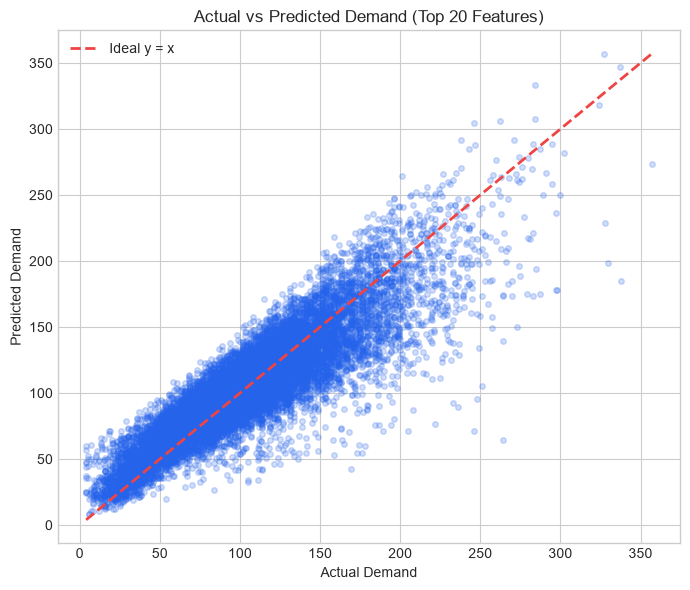

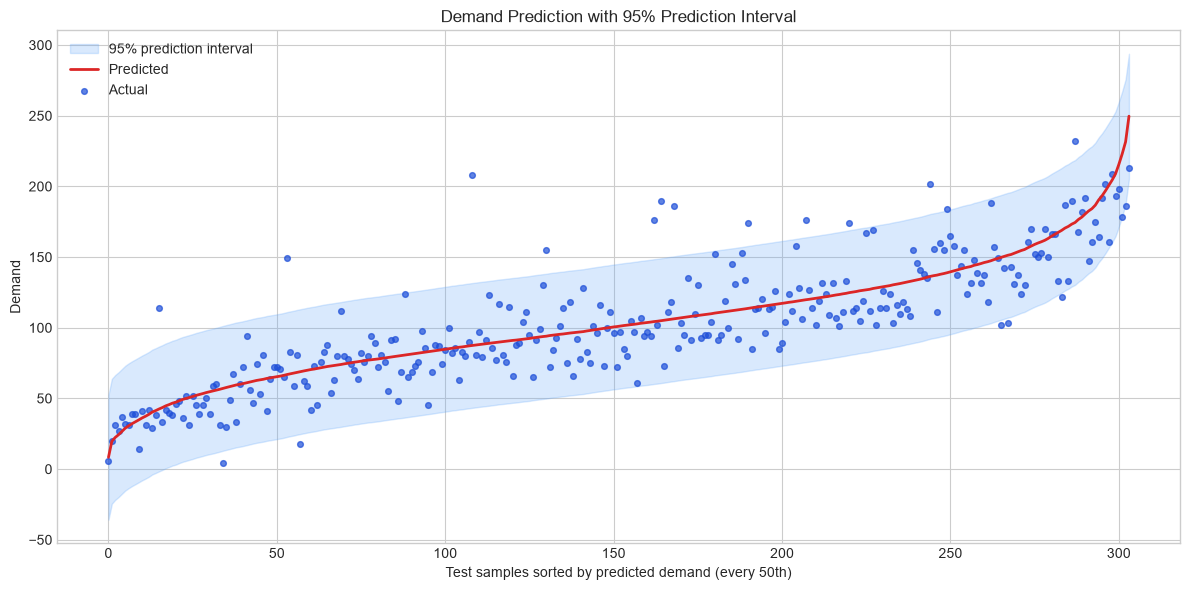

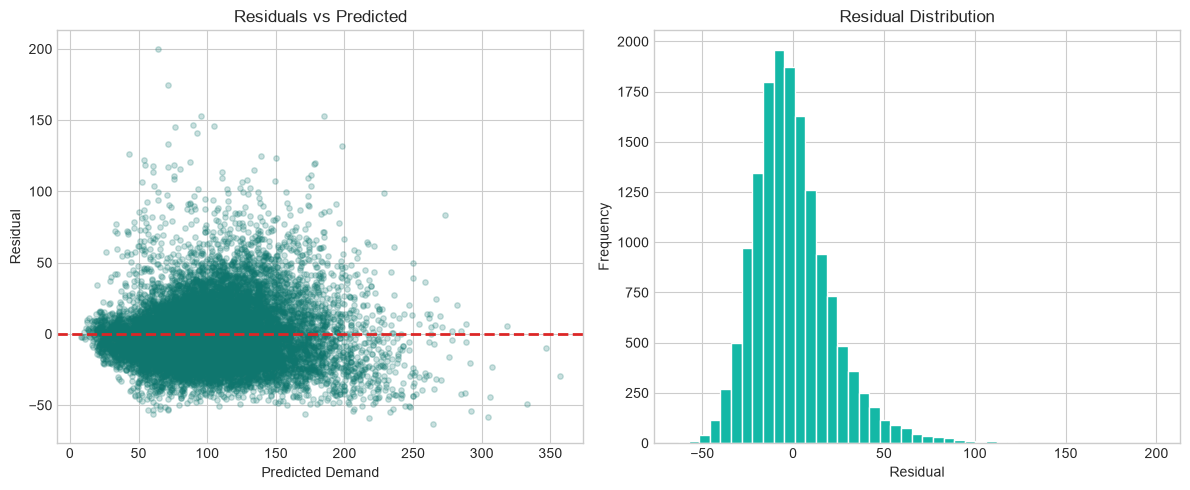

In [8]:
figure, axis = plt.subplots(figsize=(7, 6))
axis.scatter(y_test, selected_pred, alpha=0.22, s=16, color="#2563eb")
lower = min(float(y_test.min()), float(selected_pred.min()))
upper = max(float(y_test.max()), float(selected_pred.max()))
axis.plot([lower, upper], [lower, upper], "--", color="#ef4444", linewidth=2, label="Ideal y = x")
axis.set(title="Actual vs Predicted Demand (Top 20 Features)", xlabel="Actual Demand", ylabel="Predicted Demand")
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS_DIR / "actual_vs_predicted.png", dpi=180, bbox_inches="tight")
plt.show()

ordered = prediction_results.sort_values("Predicted").reset_index(drop=True)
plot_results = ordered.iloc[::50].reset_index(drop=True)
x_axis = np.arange(len(plot_results))
figure, axis = plt.subplots(figsize=(12, 6))
axis.fill_between(x_axis, plot_results["Lower_PI"], plot_results["Upper_PI"], alpha=0.24, color="#60a5fa", label="95% prediction interval")
axis.plot(x_axis, plot_results["Predicted"], color="#dc2626", linewidth=2, label="Predicted")
axis.scatter(x_axis, plot_results["Actual"], color="#1d4ed8", alpha=0.7, s=17, label="Actual")
axis.set(title="Demand Prediction with 95% Prediction Interval", xlabel="Test samples sorted by predicted demand (every 50th)", ylabel="Demand")
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS_DIR / "prediction_interval.png", dpi=180, bbox_inches="tight")
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(prediction_results["Predicted"], prediction_results["Residual"], alpha=0.22, s=15, color="#0f766e")
axes[0].axhline(0, color="#dc2626", linestyle="--", linewidth=2)
axes[0].set(title="Residuals vs Predicted", xlabel="Predicted Demand", ylabel="Residual")
axes[1].hist(prediction_results["Residual"], bins=45, color="#14b8a6", edgecolor="white")
axes[1].set(title="Residual Distribution", xlabel="Residual", ylabel="Frequency")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "residual_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Deployment（部署）

部署時應保存訓練完成的前處理器、前 20 名特徵清單與模型參數，並確保新資料沿用相同欄位與轉換順序。實務上可同時輸出點預測與預測區間上限，供安全庫存決策參考。由於本作業交付為靜態 Notebook 與報告，目前不包含持續運作的 API 或資料庫服務。

## GPT 輔助內容

GPT/Codex 協助檢查作業規格、修正資料洩漏風險、設計特徵選擇流程、建立預測區間圖與整理報告。完整對話另附 PDF，報告會清楚標示 AI 協助範圍；所有模型數值均由程式實際執行取得。

## NotebookLM 摘要

既有 NotebookLM 研究內容指出，零售需求預測除了線性回歸，也常見 Ridge/Lasso、樹模型與時間序列方法。促銷、價格、季節與庫存等外生變數能提升多變量模型的資訊量；非線性模型可能捕捉交互作用，而 ARIMA/SARIMA 類方法更重視時間相依性。本作業以容易解釋、符合課程要求的多元線性回歸為主，並將更進階方法列為後續比較方向。NotebookLM 實際操作證明仍應由使用者提供畫面或匯出紀錄。

In [9]:
print("Analysis completed.")
print("Top 20 features:")
for rank, feature in enumerate(selected_features, start=1):
    print(f"{rank:>2}. {feature}")
display(model_comparison)

Analysis completed.
Top 20 features:
 1. Units Sold
 2. Units Ordered
 3. Epidemic
 4. Category_Furniture
 5. Category_Groceries
 6. Promotion
 7. Discount
 8. Weather Condition_Sunny
 9. Inventory Level
10. Weather Condition_Rainy
11. Seasonality_Summer
12. Category_Toys
13. Product ID_P0020
14. Weather Condition_Snowy
15. Seasonality_Spring
16. Product ID_P0009
17. Product ID_P0012
18. Product ID_P0017
19. Product ID_P0013
20. Category_Electronics


,Model,Feature_Count,MAE,RMSE,R2
0,Mean baseline,0,37.041649,46.994849,-3.013392e-08
1,Linear regression - all features,44,16.266018,21.813803,7.845422e-01
2,Linear regression - top 20,20,16.551093,22.201103,7.768234e-01
